# Optical origin of wide-field angular linearity in the human eye

This notebook reproduces the main figures and results from the manuscript "Optical origin of wide-field angular linearity in the human eye" by Beenakker et al.

Run `python eye_sim.py --experiment all --mode full` first,
so `results/` contains the simulation results.

alternatively: unzip `results.zip` to use our simulation results (due to the stochastic nature of the syntheyes, small differences are expected). 

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.nonparametric.smoothers_lowess import lowess

sys.path.insert(0, ".")
import eye_sim  # noqa: E402  (only its reference-angle constants and NAVARRO_DEFAULTS are used here)

RESULTS_DIR = Path("results")

TEAL, SLATE, CORAL, GREEN, N2C = "#1f9e89", "#475569", "#e8604c", "#2e7d32", "#2166ac"
THETA_LABEL = r"Field angle $\theta$ [deg]"
RESIDUAL_LABEL = r"Deviation from identity, $\alpha_{N'} - \theta$ [deg]"


# ---- data helpers ----
def signed_err40(long_df):
    """Signed error at theta=40° for each eye_id in long_df."""
    d40 = long_df[long_df["theta"] == 40.0].set_index("eye_id")
    return (d40["angle_second_nodal_point"] - 40.0).rename("signed_err40_deg")


def spearman_table(df, specs):
    """Spearman rho of each (column, label) driver in `specs` against signed_err40_deg, sorted by |rho|."""
    rows = [
        (col, lab, spearmanr(df[col], df["signed_err40_deg"])[0]) for col, lab in specs
    ]
    return pd.DataFrame(rows, columns=["driver", "label", "rho"]).sort_values(
        "rho", key=np.abs, ascending=False
    )


# ---- plotting functions ----
def hist_panel(ax, values, xlabel, color=TEAL):
    """Histogram with the median and IQR as the panel title."""
    q1, med, q3 = np.percentile(values, [25, 50, 75])
    ax.hist(values, bins=40, color=color, edgecolor="none")
    ax.set(
        xlabel=xlabel, yticks=[], title=f"median {med:.2f}, IQR [{q1:.2f}, {q3:.2f}]"
    )


def spearman_bars(ax, rho_df, title):
    """Horizontal bar chart of a spearman_table; |rho| > 0.3 (dashed lines) counts as a strong driver."""
    r = rho_df.sort_values("rho")
    colors = [CORAL if v < -0.3 else N2C if v > 0.3 else SLATE for v in r["rho"]]
    bars = ax.barh(r["label"], r["rho"], color=colors)
    ax.bar_label(bars, fmt="%+.2f", padding=3)
    ax.set_xlim(-1.25, 1.25)  # full rho range, plus room for the value labels
    ax.axvline(0, color="k", linewidth=0.9)
    for v in (-0.3, 0.3):
        ax.axvline(v, color=SLATE, linewidth=0.8, linestyle="--")
    ax.set(xlabel=r"Spearman $\rho$ vs signed 40° error", title=title)


def hexbin_panel(ax, df, col, xlabel):
    """Signed 40-deg error vs one driver: hexbin density, LOWESS trend, Spearman rho."""
    x, y = df[col], df["signed_err40_deg"]
    ax.hexbin(x, y, gridsize=36, cmap="YlOrRd", mincnt=1)
    ax.plot(
        *lowess(y, x, frac=0.3).T,
        color=N2C,
        linewidth=2,
        label=rf"LOWESS, $\rho$={spearmanr(x, y)[0]:+.2f}",
    )
    ax.legend(loc="upper left")
    ax.set(xlabel=xlabel, ylabel="Signed 40° error [deg]")


def residual_panel(ax, long_df, color, label, bands=(95, 75, 50)):
    """Mean alpha_N' - theta over the valid traces in long_df, with central percentile bands (in %) of eyes."""
    g = long_df[long_df["valid"]].groupby("theta")["angle_second_nodal_point"]
    theta = g.mean().index.to_numpy()
    ax.plot(theta, g.mean() - theta, color=color, linewidth=2, label=label)
    for b in bands:
        ax.fill_between(
            theta,
            g.quantile(0.5 - b / 200) - theta,
            g.quantile(0.5 + b / 200) - theta,
            color=color,
            alpha=0.15,
        )


# ---- printing functions ----
def mean_sd(x, dec=2):
    return f"{np.mean(x):.{dec}f} ± {np.std(x, ddof=1):.{dec}f}"

def show(label, value):
    print(f"  {label:<58} {value}")

In [2]:
# Data loading and preprocessing

# ---- Main SyntEyes population ----
syn_summary = pd.read_csv(RESULTS_DIR / "synteyes_summary.csv")
syn_long = pd.read_csv(RESULTS_DIR / "synteyes_long.csv")
syn_summary = syn_summary.join(signed_err40(syn_long), on="eye_id")
syn_summary["cornea_back_front_ratio"] = (
    syn_summary["cornea_back_radius"] / syn_summary["cornea_front_radius"]
)

# Population-level chief-ray decomposition
syn_decomp = pd.read_csv(
    RESULTS_DIR / "synteyes_chief_ray_decomposition.csv",
    usecols=["theta", "valid", "T_ang", "T_piv", "T_ret", "total_error"],
)
navarro_decomp = pd.read_csv(RESULTS_DIR / "navarro_chief_ray_decomposition.csv")
navarro_decomp = navarro_decomp[navarro_decomp["label"] == "navarro_phakic"]

# Biometric drivers of the signed 40-deg error
DRIVER_SPECS = [
    ("central_SE", "Central refraction [D]"),
    ("axial_length_sampled", "Axial length [mm]"),
    ("retina_R", "Retinal radius R [mm]"),
    ("retina_Q", "Retinal asphericity Q"),
    ("cornea_front_radius", "Corneal radius [mm]"),
    ("cornea_front_asphericity", "Corneal asphericity k"),
    ("acd", "ACD [mm]"),
    ("rpr_40", "Relative peripheral refraction @40deg [D]"),
    ("periph_SE_40", "Absolute peripheral SE @40deg [D]"),
    ("lens_thickness", "Lens thickness [mm]"),
]
driver_rho_df = spearman_table(syn_summary, DRIVER_SPECS)

# ---- Parameter sweep ----
sw_summary = pd.read_csv(RESULTS_DIR / "parameter_sweep_summary.csv")
sw_long = pd.read_csv(
    RESULTS_DIR / "parameter_sweep_long.csv",
    usecols=["eye_id", "theta", "angle_second_nodal_point"],
)
sw_summary = sw_summary.join(signed_err40(sw_long), on="eye_id")
sw_summary["axial_length_sweep"] = (
    sw_summary["vitreous_depth"]
    + eye_sim.NAVARRO_DEFAULTS["cornea_thickness"]
    + sw_summary["acd"]
    + sw_summary["lens_thickness"]
)

SW_DRIVER_SPECS = [
    ("axial_length_sweep", "Axial length [mm]"),
    ("retina_R", "Retinal radius R [mm]"),
    ("retina_Q", "Retinal asphericity Q"),
    ("vitreous_depth", "Vitreous depth [mm]"),
    ("cornea_front_radius", "Corneal radius [mm]"),
    ("cornea_front_asphericity", "Corneal asphericity k"),
    ("acd", "ACD [mm]"),
    ("lens_thickness", "Lens thickness [mm]"),
]
sw_driver_rho_df = spearman_table(sw_summary, SW_DRIVER_SPECS)

# ---- Pseudophakic population ----
IOL_DESIGNS = {  # design name (see iol_designs.json)
    "meniscus_family_elp4.0": ("Meniscus IOL", CORAL),
    "aspheric_family_elp4.5": ("Aspheric biconvex IOL", TEAL),
}
iol_long = pd.read_csv(
    RESULTS_DIR / "synteyes_pseudophakic_long.csv",
    usecols=["design", "theta", "valid", "angle_second_nodal_point"],
)
iol_long = iol_long[iol_long["design"].isin(IOL_DESIGNS)]
assert set(IOL_DESIGNS) <= set(iol_long["design"]), (
    "IOL design missing from synteyes_pseudophakic_long.csv"
)
iol_summary = pd.read_csv(RESULTS_DIR / "synteyes_pseudophakic_summary.csv")
iol_summary = iol_summary[iol_summary["design"].isin(IOL_DESIGNS)]
iol_failed = pd.read_csv(RESULTS_DIR / "synteyes_pseudophakic_failed.csv")
iol_failed = iol_failed[iol_failed["design"].isin(IOL_DESIGNS)]

### Distribution of ocular biometry of the 3D SyntEyes population

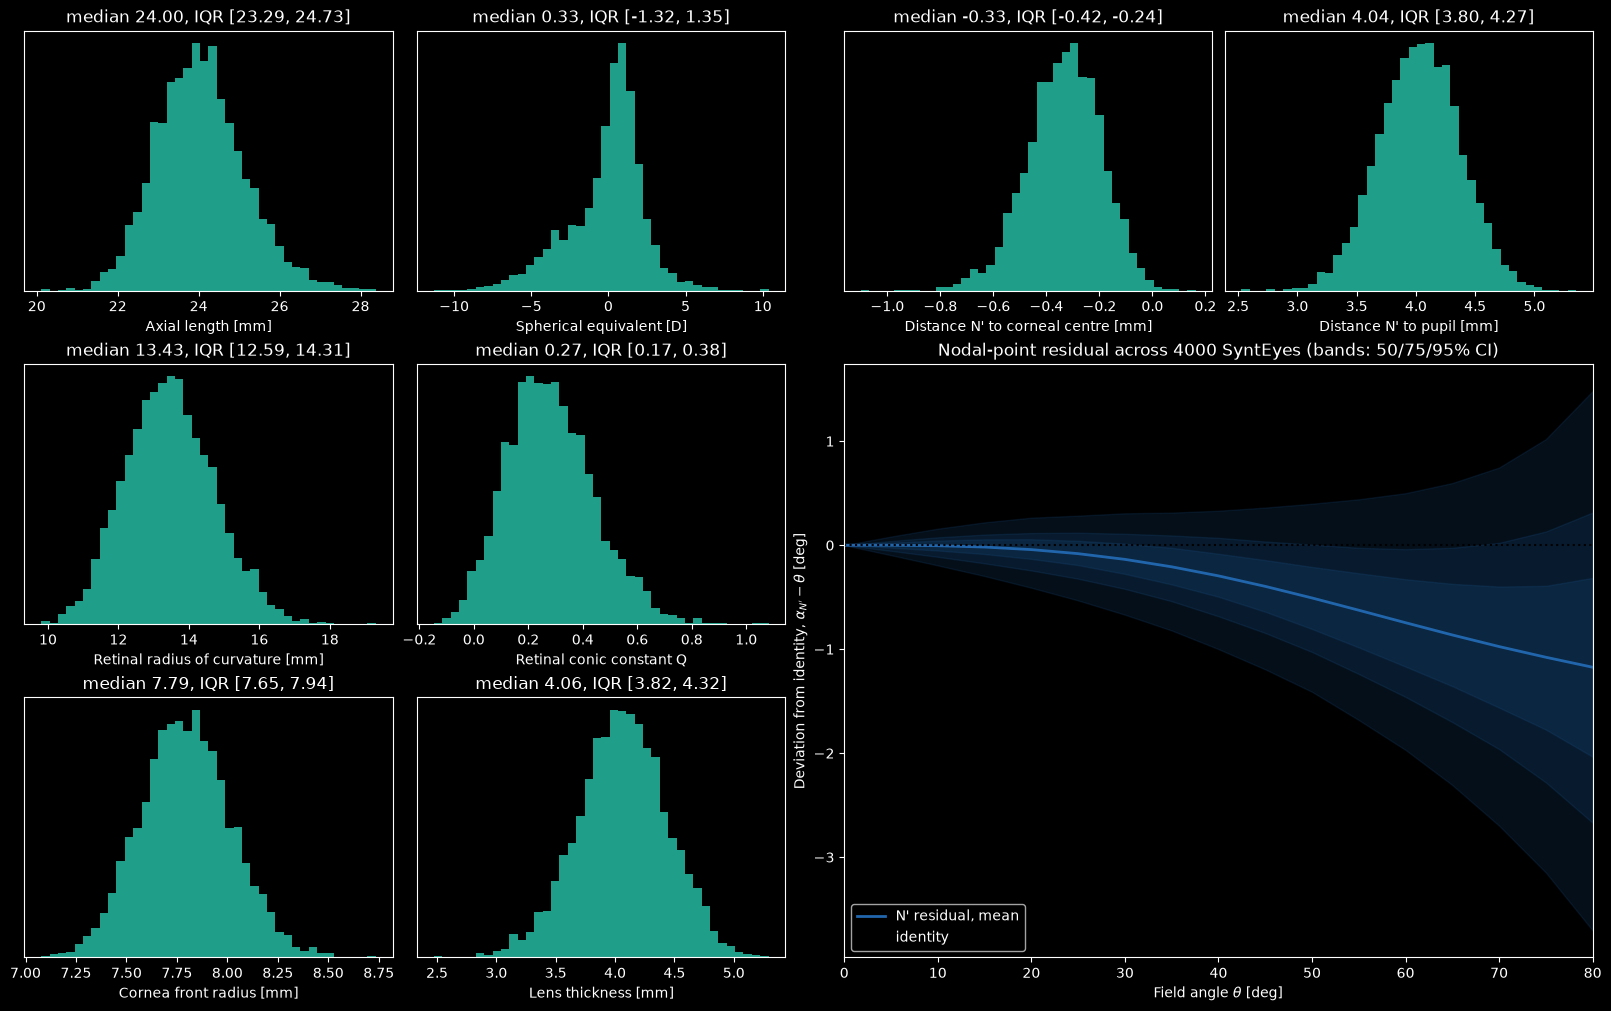

In [3]:
def cohort(summary, long_df):
    fig, ax = plt.subplot_mosaic(
        [
            ["AL", "SE", "N2_C", "N2_EP"],
            ["R", "Q", "res", "res"],
            ["Rc", "LT", "res", "res"],
        ],
        figsize=(16, 10),
        layout="constrained",
    )
    hists = {
        "AL": (summary["axial_length_sampled"], "Axial length [mm]"),
        "SE": (summary["central_SE"], "Spherical equivalent [D]"),
        "R": (summary["retina_R"], "Retinal radius of curvature [mm]"),
        "Q": (summary["retina_Q"], "Retinal conic constant Q"),
        "Rc": (summary["cornea_front_radius"], "Cornea front radius [mm]"),
        "LT": (summary["lens_thickness"], "Lens thickness [mm]"),
        "N2_C": (summary["sep_N2_corneaC"], "Distance N' to corneal centre [mm]"),
        "N2_EP": (summary["z_N2"] - summary["z_EP"], "Distance N' to pupil [mm]"),
    }
    for key, (values, xlabel) in hists.items():
        hist_panel(ax[key], values, xlabel)

    residual_panel(ax["res"], long_df, N2C, "N' residual, mean")
    ax["res"].axhline(0, color="k", linestyle=":", label="identity")
    ax["res"].set(
        xlim=(0, 80),
        xlabel=THETA_LABEL,
        ylabel=RESIDUAL_LABEL,
        title=f"Nodal-point residual across {len(summary)} SyntEyes (bands: 50/75/95% CI)",
    )
    ax["res"].legend(loc="lower left")
    return fig

cohort(syn_summary, syn_long)
plt.show()

### Chief-ray error decomposition across the 3D SyntEyes population

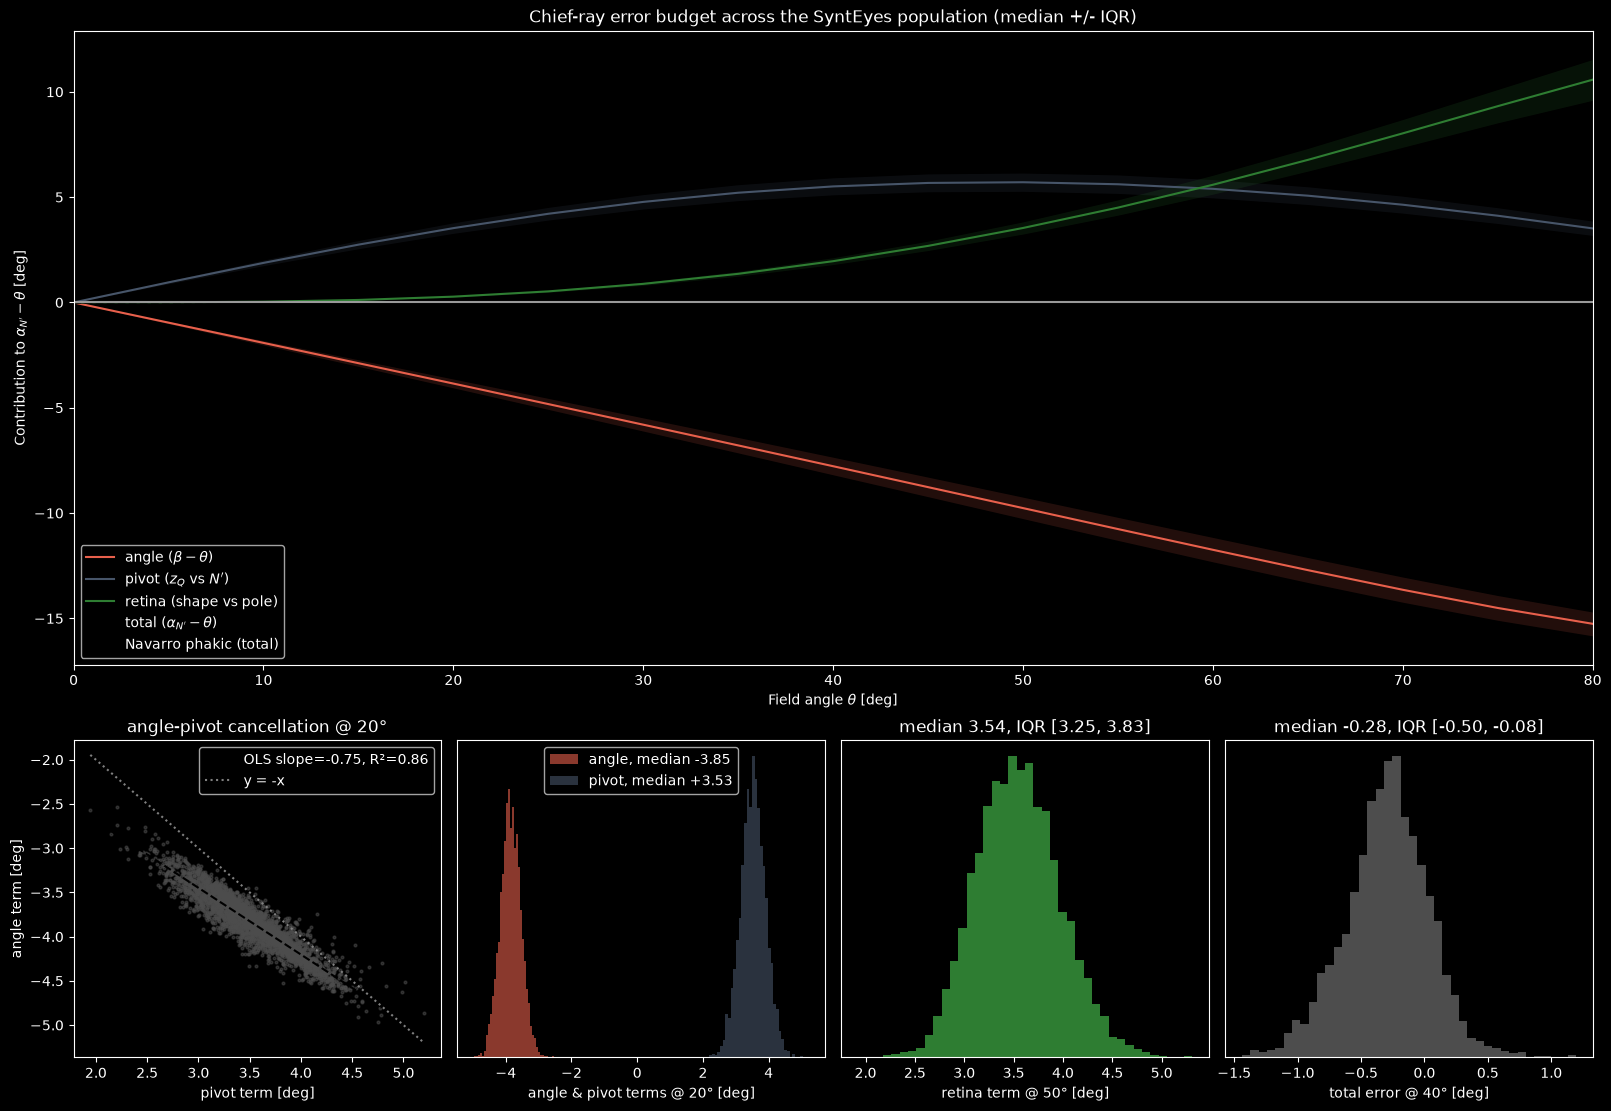

In [4]:
def chief_ray_budget(decomp, navarro_decomp, summary):
    a_ap, a_ret, a_tot = (
        eye_sim.ANGLE_PIVOT_TERM_ANGLE,
        eye_sim.RETINA_TERM_ANGLE,
        eye_sim.ERROR_MM_REFERENCE_ANGLE,
    )
    terms = {  # column -> (label, colour)
        "T_ang": (r"angle ($\beta-\theta$)", CORAL),
        "T_piv": (r"pivot ($z_Q$ vs $N'$)", SLATE),
        "T_ret": ("retina (shape vs pole)", GREEN),
        "total_error": (r"total ($\alpha_{N'}-\theta$)", "black"),
    }
    fig, ax = plt.subplot_mosaic(
        [["budget"] * 4, ["scatter", "ang_piv", "ret", "total"]],
        height_ratios=[2, 1],
        figsize=(16, 11),
        layout="constrained",
    )

    # Upper: population median +/- IQR of each term across theta
    valid = decomp[decomp["valid"]]
    for col, (label, color) in terms.items():
        g = valid.groupby("theta")[col]
        ax["budget"].fill_between(
            g.median().index,
            g.quantile(0.25),
            g.quantile(0.75),
            color=color,
            alpha=0.15,
            linewidth=0,
        )
        ax["budget"].plot(g.median(), color=color, label=label)
    nav = navarro_decomp[navarro_decomp["valid"]]
    ax["budget"].plot(
        nav["theta"], nav["total_error"], "k--", label="Navarro phakic (total)"
    )
    ax["budget"].axhline(0, color="0.6")
    ax["budget"].set(
        xlim=(0, 80),
        xlabel=THETA_LABEL,
        ylabel=r"Contribution to $\alpha_{N'} - \theta$ [deg]",
        title="Chief-ray error budget across the SyntEyes population (median +/- IQR)",
    )
    ax["budget"].legend(loc="lower left")

    # Lower row: the angle and pivot terms nearly cancel
    # then the retina term and the total error, each at its own reference angle.
    x, y = summary["T_piv_20"], summary["T_ang_20"]
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax["scatter"].scatter(x, y, s=4, color="0.3", alpha=0.5)
    ax["scatter"].plot(
        xs,
        slope * xs + intercept,
        "k--",
        label=f"OLS slope={slope:.2f}, R²={np.corrcoef(x, y)[0, 1] ** 2:.2f}",
    )
    ax["scatter"].plot(xs, -xs, ":", color="0.5", label="y = -x")
    ax["scatter"].set(
        xlabel="pivot term [deg]",
        ylabel="angle term [deg]",
        title=f"angle-pivot cancellation @ {a_ap:.0f}°",
    )
    ax["scatter"].legend()

    for col, name, color in [
        ("T_ang_20", "angle", CORAL),
        ("T_piv_20", "pivot", SLATE),
    ]:
        ax["ang_piv"].hist(
            summary[col],
            bins=40,
            color=color,
            alpha=0.6,
            edgecolor="none",
            label=f"{name}, median {summary[col].median():+.2f}",
        )
    ax["ang_piv"].set(xlabel=f"angle & pivot terms @ {a_ap:.0f}° [deg]", yticks=[])
    ax["ang_piv"].legend()

    hist_panel(
        ax["ret"], summary["T_ret_50"], f"retina term @ {a_ret:.0f}° [deg]", color=GREEN
    )
    hist_panel(
        ax["total"],
        valid.loc[valid["theta"] == a_tot, "total_error"],
        f"total error @ {a_tot:.0f}° [deg]",
        color="0.3",
    )
    return fig

chief_ray_budget(syn_decomp, navarro_decomp, syn_summary)
plt.show()

### Biometric drivers of residual mapping error

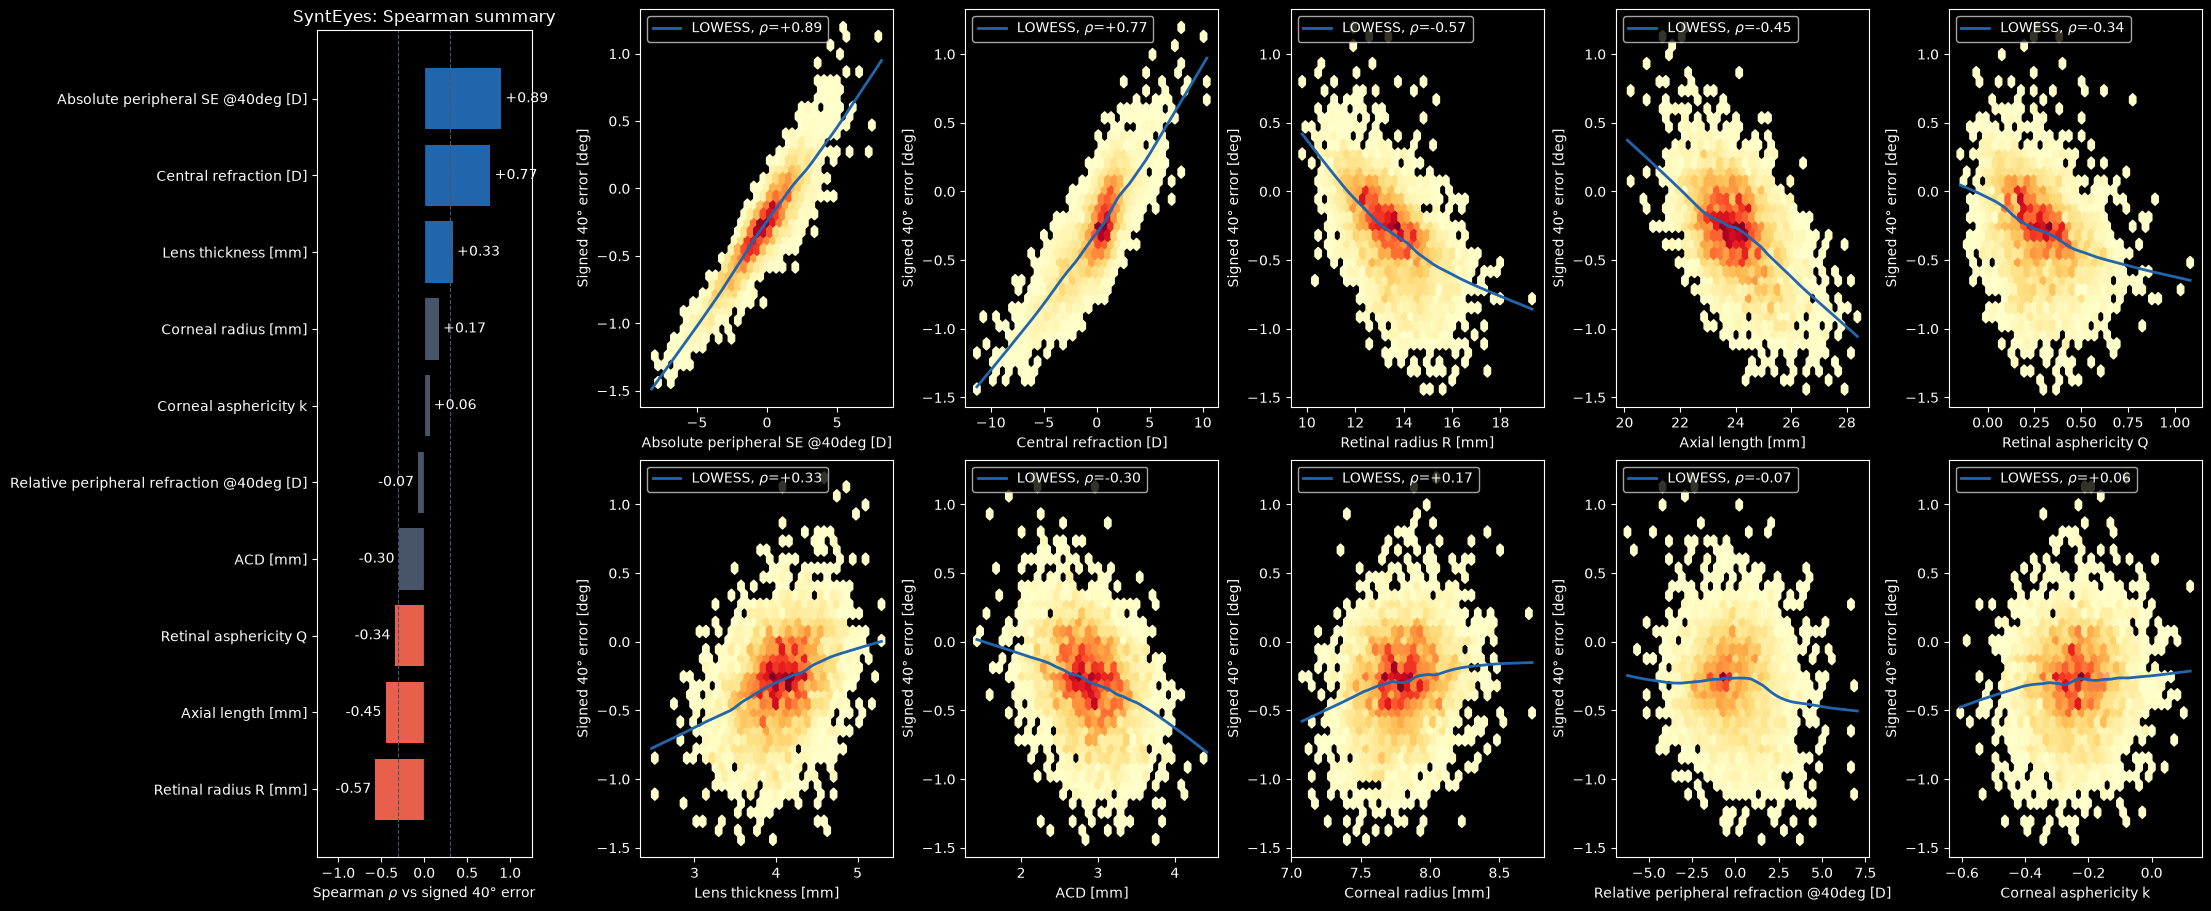

In [ ]:
def biometric_drivers(summary, rho_df):
    fig = plt.figure(figsize=(22, 9), layout="constrained")
    left, right = fig.subfigures(1, 2, width_ratios=[1, 3])
    spearman_bars(left.subplots(), rho_df, "SyntEyes: Spearman summary")
    for ax, row in zip(right.subplots(2, 5).flat, rho_df.itertuples()):
        hexbin_panel(ax, summary, row.driver, row.label)
    return fig

biometric_drivers(syn_summary, driver_rho_df)
plt.show()


### Parameter-sweep drivers and IOL nodal-point residuals

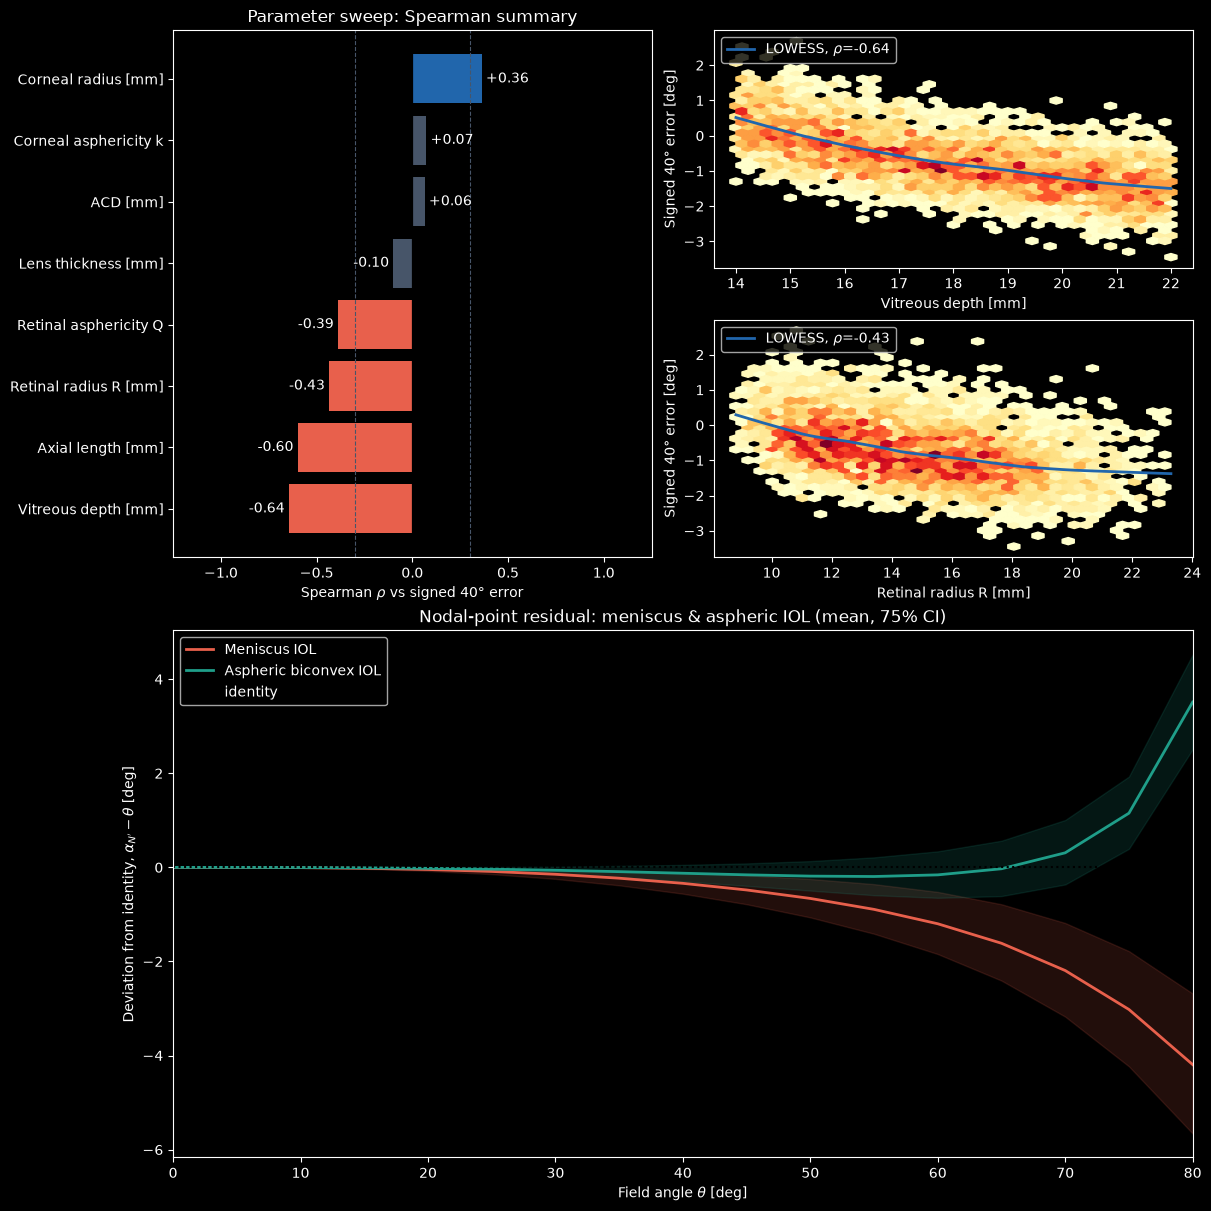

In [6]:
def sweep_drivers_and_iol(iol_long, sw_summary, sw_rho_df):
    fig, ax = plt.subplot_mosaic(
        [["rho", "vitreous"], ["rho", "retina"], ["iol", "iol"], ["iol", "iol"]],
        figsize=(12, 12),
        layout="constrained",
    )
    spearman_bars(ax["rho"], sw_rho_df, "Parameter sweep: Spearman summary")
    hexbin_panel(ax["vitreous"], sw_summary, "vitreous_depth", "Vitreous depth [mm]")
    hexbin_panel(ax["retina"], sw_summary, "retina_R", "Retinal radius R [mm]")

    for design, (label, color) in IOL_DESIGNS.items():
        residual_panel(
            ax["iol"], iol_long[iol_long["design"] == design], color, label, bands=(75,)
        )
    ax["iol"].axhline(0, color="k", linestyle=":", label="identity")
    ax["iol"].set(
        xlim=(0, 80),
        xlabel=THETA_LABEL,
        ylabel=RESIDUAL_LABEL,
        title="Nodal-point residual: meniscus & aspheric IOL (mean, 75% CI)",
    )
    ax["iol"].legend(loc="upper left")
    return fig

sweep_drivers_and_iol(iol_long, sw_summary, sw_driver_rho_df)
plt.show()

### Values reported in the manuscript

In [7]:
# ---- Table 1: SyntEyes mean (SD) and the parameter sweep's Latin-hypercube range ----
TABLE1 = [
    ("Corneal front radius (mm)", "cornea_front_radius", "cornea_front_radius"),
    (
        "Corneal front asphericity",
        "cornea_front_asphericity",
        "cornea_front_asphericity",
    ),
    (
        "Corneal back/front radius ratio",
        "cornea_back_front_ratio",
        "cornea_back_front_ratio",
    ),
    ("Anterior chamber depth (mm)", "acd", "acd"),
    ("Lens front radius (mm)", "lens_front_radius", "lens_front_radius"),
    ("Lens thickness (mm)", "lens_thickness", "lens_thickness"),
    ("Lens back radius (mm)", "lens_back_radius", "lens_back_radius"),
    ("Vitreous depth (mm)", "vitreous_depth", "vitreous_depth"),
    ("Retinal AP semi-diameter (mm)", "retina_rz", "retina_z_radius"),
    ("Retinal LR semi-diameter (mm)", "retina_rx", "retina_x_radius"),
]
table1 = pd.DataFrame(
    {
        "SyntEyes, mean (SD)": [
            f"{syn_summary[c].mean():.2f} ({syn_summary[c].std():.2f})"
            for _, c, _ in TABLE1
        ],
        "Parameter sweep, range": [
            f"{sw_summary[c].min():.2f} to {sw_summary[c].max():.2f}"
            for _, _, c in TABLE1
        ],
    },
    index=[label for label, _, _ in TABLE1],
)
display(table1)

# ---- Results 1: SyntEyes cohort ----
print("Results 1: SyntEyes cohort")
show("rays traced successfully to 80° (%)", f"{100 * syn_long['valid'].mean():.1f}")
show(
    "|N' - corneal centre| (mm), N' anterior",
    mean_sd(syn_summary["sep_N2_corneaC"].abs()),
)
syn40_deg = syn_summary["signed_err40_deg"].abs()
syn80 = syn_long[(syn_long["theta"] == 80) & syn_long["valid"]].merge(
    syn_summary, on=["eye_id", "design"]
)
z_pred, h_pred = eye_sim._predict_landing_point(
    80.0,
    syn80["z_N2"],
    1.0,
    syn80["axial_length_sampled"],
    syn80["retina_radius"],
    syn80["retina_asphericity"],
)
syn80_mm = np.hypot(z_pred - syn80["z"], h_pred - syn80["h"].abs())

show(
    "slope about N', fitted to 60°",
    mean_sd(syn_summary["slope_to_second_nodal_point"], 3),
)
show(
    "eyes with R² > 0.999 (%)",
    f"{100 * (syn_summary['r_squared_second_nodal_point'] > 0.999).mean():.1f}",
)
show("|α - θ| at 40° (deg)", mean_sd(syn40_deg))
show("|α - θ| at 40°, 95th percentile (deg)", f"{syn40_deg.quantile(0.95):.2f}")
show("|α - θ| at 80° (deg)", mean_sd((syn80["angle_second_nodal_point"] - 80).abs()))
show("position error at 40° (mm)", mean_sd(syn_summary["error_mm_40"]))
show("position error at 80° (mm)", mean_sd(syn80_mm))

# ---- Results 2: parameter sweep ----
sw40_deg = sw_summary["signed_err40_deg"].abs()
sw_rho = sw_driver_rho_df.set_index("driver")["rho"].abs()
weak = sw_rho[["cornea_front_asphericity", "acd", "lens_thickness"]]
strong = sw_rho[
    [
        "cornea_front_radius",
        "axial_length_sweep",
        "vitreous_depth",
        "retina_R",
        "retina_Q",
    ]
]
n_angles_60 = (eye_sim.ECCENTRICITIES <= eye_sim.LINEARITY_MAX_ANGLE).sum()
n_traced_60 = (sw_summary["n_valid_second_nodal_point"] == n_angles_60).sum()

print("Results 2: parameter sweep")
show("max |central SE| (D)", f"{sw_summary['central_SE'].abs().max():.1f}")
show("max axial length (mm)", f"{sw_summary['axial_length_sweep'].max():.1f}")
show(
    "eyes traced to 60°",
    f"{n_traced_60} / {len(sw_summary)} ({100 * n_traced_60 / len(sw_summary):.0f}%)",
)
show(
    "|α - θ| at 40°, median / 95th percentile (deg)",
    f"{sw40_deg.median():.2f} / {sw40_deg.quantile(0.95):.2f}",
)
show(
    "position error at 40°, median / 95th percentile (mm)",
    f"{sw_summary['error_mm_40'].median():.2f} / {sw_summary['error_mm_40'].quantile(0.95):.2f}",
)
show(
    "|ρ| corneal asphericity, ACD, lens thickness",
    f"{weak.min():.3f} to {weak.max():.3f}",
)
show(
    "|ρ| corneal radius, axial length, vitreous depth, R, Q",
    f"{strong.min():.3f} to {strong.max():.3f}",
)

# ---- Results 3: pseudophakic eyes ----
print("Results 3: pseudophakic eyes")
show(
    "eyes reaching on-axis emmetropia",
    f"{len(iol_summary)} / {len(iol_summary) + len(iol_failed)}",
)
show("max |residual refraction| (D)", f"{iol_summary['central_SE'].abs().max():.1e}")
z_N2_phakic = syn_summary.set_index("eye_id")["z_N2"]
for design, (label, _) in IOL_DESIGNS.items():
    d = iol_summary[iol_summary["design"] == design]
    rays = iol_long[(iol_long["design"] == design) & iol_long["valid"]]
    err = rays["angle_second_nodal_point"] - rays["theta"]
    err80 = err[rays["theta"] == 80]
    show(
        f"{label}: |N' shift| from the phakic eye (mm)",
        mean_sd((d["z_N2"] - d["eye_id"].map(z_N2_phakic)).abs()),
    )
    show(f"{label}: |α - θ| at 40° (deg)", mean_sd(err[rays["theta"] == 40].abs()))
    show(f"{label}: position error at 40° (mm)", mean_sd(d["error_mm_40"]))
    show(f"{label}: α - θ at 80° (deg)", f"{err80.mean():+.2f} ± {err80.std():.2f}")

,"SyntEyes, mean (SD)","Parameter sweep, range"
Corneal front radius (mm),7.80 (0.22),7.00 to 8.60
Corneal front asphericity,-0.24 (0.10),-0.80 to 0.10
Corneal back/front radius ratio,0.82 (0.02),0.70 to 0.95
Anterior chamber depth (mm),2.88 (0.39),1.80 to 4.40
Lens front radius (mm),10.55 (1.19),6.00 to 14.00
Lens thickness (mm),4.06 (0.38),3.00 to 6.00
Lens back radius (mm),-6.95 (0.75),-10.00 to -4.00
Vitreous depth (mm),16.56 (1.04),14.00 to 22.00
Retinal AP semi-diameter (mm),10.55 (0.60),9.10 to 12.40
Retinal LR semi-diameter (mm),11.90 (0.54),10.40 to 14.60


Results 1: SyntEyes cohort
  rays traced successfully to 80° (%)                        100.0
  |N' - corneal centre| (mm), N' anterior                    0.33 ± 0.14
  slope about N', fitted to 60°                              0.991 ± 0.009
  eyes with R² > 0.999 (%)                                   100.0
  |α - θ| at 40° (deg)                                       0.36 ± 0.27
  |α - θ| at 40°, 95th percentile (deg)                      0.88
  |α - θ| at 80° (deg)                                       1.45 ± 1.01
  position error at 40° (mm)                                 0.10 ± 0.08
  position error at 80° (mm)                                 0.35 ± 0.26
Results 2: parameter sweep
  max |central SE| (D)                                       28.3
  max axial length (mm)                                      32.6
  eyes traced to 60°                                         3629 / 4000 (91%)
  |α - θ| at 40°, median / 95th percentile (deg)             0.86 / 2.06
  position error at 40